> https://github.com/nmcassa/letterboxdpy

> https://letterboxd.com/


> **Sobre a biblioteca:** `Movie(slug).get_reviews()`
>  é um stub incompleto na versão atual, sempre retorna vazio. O que
**funciona de
> verdade** é `Movie(slug).popular_reviews`, preenchido automaticamente ao instanciar `Movie`: ele lê a
> seção "Popular Reviews" já presente na página do filme. Duas limitações a ter em mente:
> - **sem paginação** — só traz as resenhas exibidas naquela seção da página (não dá pra pedir mais páginas);
> - **só o primeiro parágrafo** de cada resenha é capturado pelo parser da biblioteca.
>
> Por isso, para ganhar volume e variedade (critério do template), a coleta varia os **filmes**
> (populares + vários gêneros) em vez de tentar paginar resenhas de um único filme.


In [ ]:
!pip install -q git+https://github.com/nmcassa/letterboxdpy.git

!pip install -q nltk langdetect unidecode pandas tqdm

ERROR: Operation cancelled by user


In [ ]:
import re
import time
import json
from pathlib import Path

import pandas as pd
from tqdm.auto import tqdm
from langdetect import detect, DetectorFactory, LangDetectException

import nltk
nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)
nltk.download("stopwords", quiet=True)
nltk.download("rslp", quiet=True)
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import RSLPStemmer, SnowballStemmer

from letterboxdpy.films import Films, get_movies_by_genre
from letterboxdpy.movie import Movie
from letterboxdpy.core.exceptions import (
    PrivateRouteError,
    ResourceNotFoundError,
    AccessDeniedError,
    InvalidResponseError,
    PageLoadError,
)

DetectorFactory.seed = 42


In [ ]:
GENEROS = [
    "action", "comedy", "drama", "horror", "romance",
    "science-fiction", "documentary", "animation", "adventure",
    "crime", "family", "fantasy", "thriller", "history", "music",
    "tv-movie", "war", "western", "musical"
]
MAX_POR_LISTA = 10       # filmes por lista (populares + cada gênero)
PAUSA_ENTRE_REQS = 1.0   # segundos entre requisições, para não sobrecarregar o servidor
ARQ_BRUTO = Path("resenhas_letterboxd_bruto.csv")

print("Buscando filmes populares...")
filmes = dict(Films("https://letterboxd.com/films/popular/", max=MAX_POR_LISTA).movies)

for genero in GENEROS:
    print(f"Buscando filmes do gênero '{genero}'...")
    filmes |= get_movies_by_genre(genero, max=MAX_POR_LISTA)
    time.sleep(PAUSA_ENTRE_REQS)

slugs = sorted({info["slug"] for info in filmes.values()})
print(f"\n{len(slugs)} filmes únicos reunidos (populares + {len(GENEROS)} gêneros).")


Buscando filmes populares...
Buscando filmes do gênero 'action'...
Buscando filmes do gênero 'comedy'...


AccessDeniedError: IP or VPN Blocked: Letterboxd is blocking this request. Try disabling your VPN/Proxy.: https://letterboxd.com/csi/films/films-browser-list/genre/comedy/page/1/
Hint: If you are using a VPN or Proxy, Letterboxd might be blocking your connection. Try disabling it.

In [ ]:
def coletar_resenhas_por_filme(slugs, pausa=PAUSA_ENTRE_REQS):
    registros = []
    erros = []

    for slug in tqdm(slugs, desc="Coletando por filme"):
        try:
            m = Movie(slug)
        except (PrivateRouteError, ResourceNotFoundError, AccessDeniedError,
                InvalidResponseError, PageLoadError) as e:
            erros.append({"filme_slug": slug, "erro": str(type(e).__name__)})
            continue
        except Exception as e:
            erros.append({"filme_slug": slug, "erro": f"inesperado: {e}"})
            continue

        generos = [g["name"] for g in (m.genres or [])]
        diretores = [d["name"] for d in m.crew.get("director", [])] if m.crew else []

        for rev in (m.popular_reviews or []):
            texto = rev.get("review")
            if not texto:
                continue
            registros.append({
                "filme": m.title,
                "filme_slug": slug,
                "ano_lancamento": m.year,
                "generos": generos,
                "diretores": diretores,
                "nota_media_letterboxd": m.rating,
                "usuario": (rev.get("user") or {}).get("username"),
                "nota_resenha": rev.get("rating"),
                "link": rev.get("link"),
                "resenha_original": texto,
            })

        time.sleep(pausa)

    return registros, erros

registros, erros_coleta = coletar_resenhas_por_filme(slugs)
print(f"\n{len(registros)} resenhas coletadas | {len(erros_coleta)} filmes pulados por erro.")


Coletando por filme:   0%|          | 0/124 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [ ]:
df = pd.DataFrame(registros)
df.drop_duplicates(subset=["filme_slug", "usuario", "resenha_original"], inplace=True)
df.to_csv(ARQ_BRUTO, index=False, encoding="utf-8")
print(f"Base bruta salva em: {ARQ_BRUTO.resolve()}")
df.head()


In [ ]:
STOPWORDS_PT = set(stopwords.words("portuguese"))
STOPWORDS_EN = set(stopwords.words("english"))

stemmer_pt = RSLPStemmer()
stemmer_en = SnowballStemmer("english")

def limpar_ruido(texto):
    texto = re.sub(r"<[^>]+>", " ", texto)
    texto = re.sub(r"http\S+|www\.\S+", " ", texto)
    texto = re.sub(r"\s+", " ", texto).strip()
    return texto

def detectar_idioma(texto):
    try:
        return detect(texto)
    except LangDetectException:
        return "desconhecido"

def tokenizar_e_limpar(texto, idioma):
    texto = texto.lower()
    tokens = word_tokenize(texto)
    tokens = [t for t in tokens if t.isalpha()]

    if idioma == "pt":
        stop = STOPWORDS_PT
    elif idioma == "en":
        stop = STOPWORDS_EN
    else:
        stop = set()

    return [t for t in tokens if t not in stop]

def aplicar_stemming(tokens, idioma):
    if idioma == "pt":
        return [stemmer_pt.stem(t) for t in tokens]
    if idioma == "en":
        return [stemmer_en.stem(t) for t in tokens]
    return tokens


In [ ]:
tqdm.pandas()

df["resenha_limpa"] = df["resenha_original"].progress_apply(limpar_ruido)
df = df[df["resenha_limpa"].str.len() > 0].copy()

df["idioma"] = df["resenha_limpa"].progress_apply(detectar_idioma)
df["tokens"] = df.progress_apply(lambda r: tokenizar_e_limpar(r["resenha_limpa"], r["idioma"]), axis=1)
df["tokens_stemizados"] = df.progress_apply(lambda r: aplicar_stemming(r["tokens"], r["idioma"]), axis=1)

print("Distribuição de idiomas detectados:")
print(df["idioma"].value_counts())
df[["filme", "resenha_original", "idioma", "tokens"]].head()


## Dicionário de dados


| Coluna | Tipo | Descrição |
|---|---|---|
| `filme` | str | Título do filme |
| `filme_slug` | str | Slug do filme no Letterboxd |
| `ano_lancamento` | int | Ano de lançamento do filme |
| `generos` | list[str] | Gêneros do filme |
| `diretores` | list[str] | Diretor(es) do filme |
| `nota_media_letterboxd` | float | Nota média do filme na plataforma |
| `usuario` | str | Nome de usuário de quem escreveu a resenha |
| `nota_resenha` | float | Nota dada pelo usuário naquela resenha (0.5 a 5.0) |
| `link` | str | URL da resenha |
| `resenha_original` | str | Texto bruto da resenha, como coletado (primeiro parágrafo) |
| `resenha_limpa` | str | Texto após remoção de ruído (HTML, URLs, espaços) |
| `idioma` | str | Idioma detectado (`pt`, `en`, outro código ISO ou `desconhecido`) |
| `tokens` | list[str] | Tokens após normalização, tokenização e remoção de stopwords |
| `tokens_stemizados` | list[str] | Tokens após stemming (bonus) |


In [ ]:
ARQ_FINAL = Path("resenhas_letterboxd_processado.csv")

df_export = df.copy()
df_export["tokens"] = df_export["tokens"].apply(json.dumps, ensure_ascii=False)
df_export["tokens_stemizados"] = df_export["tokens_stemizados"].apply(json.dumps, ensure_ascii=False)
df_export["generos"] = df_export["generos"].apply(lambda x: json.dumps(x, ensure_ascii=False) if isinstance(x, list) else x)
df_export["diretores"] = df_export["diretores"].apply(lambda x: json.dumps(x, ensure_ascii=False) if isinstance(x, list) else x)

df_export.to_csv(ARQ_FINAL, index=False, encoding="utf-8")
print(f"Base final salva em: {ARQ_FINAL.resolve()}")
print(f"Total de resenhas no dataset final: {len(df_export)}")
print(f"Total de filmes distintos: {df_export['filme_slug'].nunique()}")


In [ ]:
import pandas as pd
from google.colab import files

# Selecionar o arquivo CSV no computador
uploaded = files.upload()

# Nome do arquivo enviado
nome_arquivo = next(iter(uploaded))

# Carregar os dados
df = pd.read_csv(nome_arquivo)

# Visualizar as primeiras linhas
df.head()

Saving resenhas_letterboxd_processado (6).csv to resenhas_letterboxd_processado (6) (2).csv


,filme,filme_slug,ano_lancamento,generos,diretores,nota_media_letterboxd,usuario,nota_resenha,link,resenha_original,resenha_limpa,idioma,tokens,tokens_stemizados
0,10 Things I Hate About You,10-things-i-hate-about-you,1999,"[""Comedy"", ""Drama"", ""Romance"", ""Underdogs and ...","[""Gil Junger""]",4.07,riverjphoenix,5.0,https://letterboxd.com/riverjphoenix/film/10-t...,the moral of the story is that all men are evi...,the moral of the story is that all men are evi...,en,"[""moral"", ""story"", ""men"", ""evil"", ""except"", ""h...","[""moral"", ""stori"", ""men"", ""evil"", ""except"", ""h..."
1,10 Things I Hate About You,10-things-i-hate-about-you,1999,"[""Comedy"", ""Drama"", ""Romance"", ""Underdogs and ...","[""Gil Junger""]",4.07,riverjphoenix,5.0,https://letterboxd.com/riverjphoenix/film/10-t...,kat stratford is the most relatable character ...,kat stratford is the most relatable character ...,en,"[""kat"", ""stratford"", ""relatable"", ""character"",...","[""kat"", ""stratford"", ""relat"", ""charact"", ""time..."
2,10 Things I Hate About You,10-things-i-hate-about-you,1999,"[""Comedy"", ""Drama"", ""Romance"", ""Underdogs and ...","[""Gil Junger""]",4.07,vortexd,5.0,https://letterboxd.com/vortexd/film/10-things-...,me: i hate cliches,me: i hate cliches,en,"[""hate"", ""cliches""]","[""hate"", ""clich""]"
3,10 Things I Hate About You,10-things-i-hate-about-you,1999,"[""Comedy"", ""Drama"", ""Romance"", ""Underdogs and ...","[""Gil Junger""]",4.07,sapphical,5.0,https://letterboxd.com/sapphical/film/10-thing...,funny how shakespeare’s been real quiet since ...,funny how shakespeare’s been real quiet since ...,en,"[""funny"", ""shakespeare"", ""real"", ""quiet"", ""sin...","[""funni"", ""shakespear"", ""real"", ""quiet"", ""sinc..."
4,10 Things I Hate About You,10-things-i-hate-about-you,1999,"[""Comedy"", ""Drama"", ""Romance"", ""Underdogs and ...","[""Gil Junger""]",4.07,jay,3.5,https://letterboxd.com/jay/film/10-things-i-ha...,heath ledger: *dances down steps with giant le...,heath ledger: *dances down steps with giant le...,en,"[""heath"", ""ledger"", ""dances"", ""steps"", ""giant""...","[""heath"", ""ledger"", ""danc"", ""step"", ""giant"", ""..."


In [ ]:
from sklearn.feature_extraction.text import CountVectorizer
import json

# só converte se ainda for texto JSON (evita erro ao reexecutar a célula)
if isinstance(df['tokens'].iloc[0], str):
    df['tokens'] = df['tokens'].apply(json.loads)

bow_vectorizer = CountVectorizer(
    analyzer=lambda tokens: tokens
)

bow_matrix = bow_vectorizer.fit_transform(
    df["tokens"]
)

bow_palavras = bow_vectorizer.get_feature_names_out()

df_bow = pd.DataFrame(
    bow_matrix.toarray(),
    columns=bow_palavras
)

df_bow.insert(0, "id", df.index.values)

df_bow.head()

,id,a,aaaa,aaaghahohahaghhaaaaahhhhh,aaron,abandoned,abbott,ability,able,abroad,...,zimmer,zohran,zone,zuckerberg,écoust,œuvre,ノ,ヽ,丿,ﾚ
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Criar o modelo TF-IDF
tfidf_vectorizer = TfidfVectorizer(
    analyzer=lambda tokens: tokens
)

# Criar a matriz TF-IDF
tfidf_matrix = tfidf_vectorizer.fit_transform(
    df["tokens"]
)

# Recuperar o vocabulário
tfidf_palavras = tfidf_vectorizer.get_feature_names_out()

# Transformar a matriz em DataFrame
df_tfidf = pd.DataFrame(
    tfidf_matrix.toarray(),
    columns=tfidf_palavras
)

# Adicionar o ID para conectar com a base original
df_tfidf.insert(0, "id", df.index.values)

# Visualizar
df_tfidf.head(20)

,id,a,aaaa,aaaghahohahaghhaaaaahhhhh,aaron,abandoned,abbott,ability,able,abroad,...,zimmer,zohran,zone,zuckerberg,écoust,œuvre,ノ,ヽ,丿,ﾚ
0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0
1,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0
2,2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0
3,3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0
4,4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0
5,5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0
6,6,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0
7,7,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0
8,8,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0
9,9,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0


In [ ]:
from sklearn.metrics.pairwise import cosine_similarity

# -------------------------------------------------
# Similaridade a partir do Bag of Words
# -------------------------------------------------

similaridade_bow = cosine_similarity(
    df_bow.drop(columns="id")
)

df_sim_bow = pd.DataFrame(
    similaridade_bow,
    index=df["filme"],
    columns=df["filme"]
)


# -------------------------------------------------
# Similaridade a partir do TF-IDF
# -------------------------------------------------

similaridade_tfidf = cosine_similarity(
    df_tfidf.drop(columns="id")
)

df_sim_tfidf = pd.DataFrame(
    similaridade_tfidf,
    index=df["filme"],
    columns=df["filme"]
)

In [ ]:
df_sim_tfidf.head()

filme,10 Things I Hate About You,10 Things I Hate About You,10 Things I Hate About You,10 Things I Hate About You,10 Things I Hate About You,10 Things I Hate About You,10 Things I Hate About You,10 Things I Hate About You,10 Things I Hate About You,10 Things I Hate About You,...,You Can See Everything,You Can See Everything,You Can See Everything,You Can See Everything,You Can See Everything,You Can See Everything,You Can See Everything,You Can See Everything,You Can See Everything,You Can See Everything
filme,,,,,,,,,,,,,,,,,,,,,
10 Things I Hate About You,1.000000,0.326289,0.0,0.112607,0.222857,0.043095,0.333284,0.147095,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.083648,0.0,0.0,0.0
10 Things I Hate About You,0.326289,1.000000,0.0,0.000000,0.214690,0.041515,0.321070,0.141705,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0
10 Things I Hate About You,0.000000,0.000000,1.0,0.000000,0.000000,0.133514,0.000000,0.000000,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0
10 Things I Hate About You,0.112607,0.000000,0.0,1.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0
10 Things I Hate About You,0.222857,0.214690,0.0,0.000000,1.000000,0.000000,0.305996,0.177751,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0


In [ ]:
from sklearn.metrics.pairwise import cosine_similarity
import pandas as pd

def matriz_similaridade(df_vetores):
    sim = cosine_similarity(df_vetores.drop(columns="id"))
    return pd.DataFrame(
        sim,
        index=df_vetores["id"],
        columns=df_vetores["id"]
    )

df_sim_bow = matriz_similaridade(df_bow)
df_sim_tfidf = matriz_similaridade(df_tfidf)
df_sim_bow.index.name = None
df_sim_bow.columns.name = None
df_sim_bow.head()

,0,1,2,3,4,5,6,7,8,9,...,1372,1373,1374,1375,1376,1377,1378,1379,1380,1381
0,1.000000,0.348155,0.0,0.095346,0.246183,0.064282,0.369274,0.150756,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.123091,0.0,0.0,0.0
1,0.348155,1.000000,0.0,0.000000,0.235702,0.061546,0.353553,0.144338,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0
2,0.000000,0.000000,1.0,0.000000,0.000000,0.150756,0.000000,0.000000,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0
3,0.095346,0.000000,0.0,1.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0
4,0.246183,0.235702,0.0,0.000000,1.000000,0.000000,0.333333,0.204124,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0


In [ ]:
from sklearn.cluster import KMeans

# Número inicial de clusters
k = 4

# Criar e ajustar o modelo
kmeans = KMeans(
    n_clusters=k,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(tfidf_matrix)

# Adicionar o resultado ao dataframe original
df["cluster"] = clusters

# Visualizar os resultados criando a coluna 'id' a partir do index para exibição
df.reset_index(names="id")[
    ["id", "filme", "resenha_limpa", "cluster"]
].sort_values("cluster")

,id,filme,resenha_limpa,cluster
1378,1378,You Can See Everything,Scarier dinner table scene than resident evil 7,0
16,16,1917,his fitbit numbers would’ve been through the roof,0
18,18,1917,wait where was harry styles???,0
19,19,1917,What Deakins was able to pull off here is real...,0
20,20,1917,Got milk?,0
...,...,...,...,...
1033,1033,Stop Making Sense,The most joyous film ever made. The little mom...,3
1026,1026,Spirited Away,maybe definitely the best animated film of all...,3
1007,1007,Spider-Man: No Way Home,"the whole theatre ERUPTED, ya’ll know when.i c...",3
1370,1370,You Can See Everything,Yes it’s about Elizabeth Holmes but really it’...,3


In [ ]:
comparacao_clusters = pd.crosstab(
    df["resenha_limpa"],
    df["cluster"]
)

comparacao_clusters

cluster,0,1,2,3
resenha_limpa,,,,
"""Chad Charming"" is the greatest name for a character in cinema history",1,0,0,0
"""Comfort film"" and its just these fucking guys my pookies",0,0,0,1
"""Every gun makes its own tune.""",1,0,0,0
"""He's just a man, Peter. Only another man.""",1,0,0,0
"""I don't get it. Why are they confessing?""""They're not confessing. They're bragging.""Best Editing Academy Award Winner 2027. Intriguing and under-examined through line on Fielder’s work about how much the lines begin to blur for him specifically as soon as women and the attention of women are involved. As someone with a fallible memory and a fear of losing it further, I’m always deeply fascinated by documentaries and stories that try to examine the limits of memory and communication with regards to our ability to tell the truth, even when we are doing our best to do so with sincerity. Anything else I want to say about this movie and the feelings it gave me towards its subjects and the entire industry of tech would be socially and legally inadvisable.",0,1,0,0
...,...,...,...,...
⠀⠀ )⠀ ) ⠀ \⠀/ 👀 (⠀\(🔥)/,1,0,0,0
⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⣠⡴⠒⠒⠲⠶⢤⣄⡀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⢀⣀⣀⣀⣀⣤⡤⠶⠛⠉⠀⠀⠀⠀⠀⠀⠀⠙⢶⡄⠀⠀⠀⠀⠀⠀⢀⣤⠖⠛⠉⠉⠁⠀⠀⠀⠠⡀⠀⠀⢢⠀⠀⠀⠀⠀⠀⠀⠀⠹⡆⠀⠀⠀⢀⡴⠋⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⡇⠀⠀⣸⠇⠀⠀⠀⠀⠀⠀⠀⠀⢸⡀⠀⢠⡾⠁⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠁⠀⠀⠋⠀⠀⠀⠀⠀⠀⠀⡠⢠⠀⢳⡀⣼⠁⠀⠀⠀⠀⣠⣶⣶⣄⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⢀⣼⣿⣾⣧⠀⣇⣿⠀⠀⠀⠀⠀⠙⠻⠟⠃⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠎⣾⣿⣿⣿⣿⠀⢸⢹⡀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⡀⠀⠀⠀⠸⢸⣿⣿⣿⣿⣿⠀⡸⠀⠱⣄⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⢠⠃⠀⠀⠀⡇⣿⣿⣿⣿⣿⠃⢀⠃⠀⠀⠀⠑⠢⠤⣄⣀⡀⠀⠀⠀⠀⣀⠤⠚⠁⠀⠀⠀⠀⢇⠹⣿⣿⡿⠃⡠⠊⠀⠀⠀⠀⠀⠀⠀⠀⠀⠉⢧⡻⡋⢅⠀⠀⠀⠀⠀⣠⠔⠊⠑⠤⠈⠡⠤⠊⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠈⠀⡠⣃⡀⢀⣀⢸⠁⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⢀⠟⠉⠁⠈⠉⠸⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⢠⠇⠀⠀⠀⠀⠀⢰⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⡟⠀⠀⠀⠀⠀⠀⠀⢢⡀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⢰⡇⠀⠀⠀⠀⠀⠀⠀⠀⠙⠦⣀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⣸⡇⠀⠀⠀⠀⡆⠀⠀⠀⢀⠀⠈⢷⡀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⢀⡤⠖⠛⠉⡩⠤⠐⠒⠒⠒⠀⠀⠀⠀⡇⠀⠀⢸⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⢠⠃⠀⡀⠀⡎⠀⢀⡄⠀⠀⠀⠀⠀⠀⠀⢸⠄⠀⢲⣭⠙⠲⡄⠀⠀⠀⠀⠀⠀⠸⣆⣀⣃⣀⣃⡀⠸⠀⠀⠇⠀⠀⠀⠀⣀⣘⣀⣀⠘⠁⠀⢀⡿⠀⠀⠀⠀⠀⠀⠀⠀⠉⠉⠉⠉⠛⠛⠛⠛⠛⠛⠛⠛⠛⠉⠉⠉⠙⢦⡴⠾⠋⠀⠀⠀⠀,1,0,0,0
⢀⡴⠑⡄⠀⠀⠀⠀⠀⠀⠀⣀⣀⣤⣤⣤⣀⡀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀ ⠸⡇⠀⠿⡀⠀⠀⠀⣀⡴⢿⣿⣿⣿⣿⣿⣿⣿⣷⣦⡀⠀⠀⠀⠀⠀⠀⠀⠀⠀ ⠀⠀⠀⠀⠑⢄⣠⠾⠁⣀⣄⡈⠙⣿⣿⣿⣿⣿⣿⣿⣿⣆⠀⠀⠀⠀⠀⠀⠀⠀ ⠀⠀⠀⠀⢀⡀⠁⠀⠀⠈⠙⠛⠂⠈⣿⣿⣿⣿⣿⠿⡿⢿⣆⠀⠀⠀⠀⠀⠀⠀ ⠀⠀⠀⢀⡾⣁⣀⠀⠴⠂⠙⣗⡀⠀⢻⣿⣿⠭⢤⣴⣦⣤⣹⠀⠀⠀⢀⢴⣶⣆ ⠀⠀⢀⣾⣿⣿⣿⣷⣮⣽⣾⣿⣥⣴⣿⣿⡿⢂⠔⢚⡿⢿⣿⣦⣴⣾⠁⠸⣼⡿ ⠀⢀⡞⠁⠙⠻⠿⠟⠉⠀⠛⢹⣿⣿⣿⣿⣿⣌⢤⣼⣿⣾⣿⡟⠉⠀⠀⠀⠀⠀ ⠀⣾⣷⣶⠇⠀⠀⣤⣄⣀⡀⠈⠻⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⡇⠀⠀⠀⠀⠀⠀ ⠀⠉⠈⠉⠀⠀⢦⡈⢻⣿⣿⣿⣶⣶⣶⣶⣤⣽⡹⣿⣿⣿⣿⡇⠀⠀⠀⠀⠀⠀ ⠀⠀⠀⠀⠀⠀⠀⠉⠲⣽⡻⢿⣿⣿⣿⣿⣿⣿⣷⣜⣿⣿⣿⡇⠀⠀⠀⠀⠀⠀ ⠀⠀⠀⠀⠀⠀⠀⠀⢸⣿⣿⣷⣶⣮⣭⣽⣿⣿⣿⣿⣿⣿⣿⠀⠀⠀⠀⠀⠀⠀ ⠀⠀⠀⠀⠀⠀⣀⣀⣈⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⠇⠀⠀⠀⠀⠀⠀⠀ ⠀⠀⠀⠀⠀⠀⢿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⠃⠀⠀⠀⠀⠀⠀⠀⠀ ⠀⠀⠀⠀⠀⠀⠀⠹⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⡿⠟⠁⠀⠀⠀⠀⠀⠀⠀⠀⠀ ⠀⠀⠀⠀⠀⠀⠀⠀⠀⠉⠛⠻⠿⠿⠿⠿⠛⠉,1,0,0,0


In [ ]:
# Contagem de filmes únicos por cluster
filmes_por_cluster = df.groupby("cluster")["filme"].nunique().reset_index(name="quantidade_filmes_unicos")

# Adicionando também a contagem total de resenhas por cluster para comparação
resenhas_por_cluster = df.groupby("cluster").size().reset_index(name="total_resenhas")

# Combinar os resultados
analise_clusters = pd.merge(filmes_por_cluster, resenhas_por_cluster, on="cluster")
display(analise_clusters)

,cluster,quantidade_filmes_unicos,total_resenhas
0,0,117,1026
1,1,89,193
2,2,20,28
3,3,77,135


In [ ]:
from sklearn.decomposition import PCA
import plotly.express as px
import pandas as pd

# Reduzir o TF-IDF para duas dimensões
pca_2d = PCA(n_components=2)

coordenadas_2d = pca_2d.fit_transform(
    tfidf_matrix.toarray()
)

# Criar um DataFrame para a visualização com as colunas corretas do Letterboxd
df_pca_2d = pd.DataFrame({
    "id": df.index,
    "filme": df["filme"],
    "generos": df["generos"],
    "resenha_limpa": df["resenha_limpa"],
    "cluster": df["cluster"].astype(str),
    "PCA1": coordenadas_2d[:, 0],
    "PCA2": coordenadas_2d[:, 1]
})

# Criar o gráfico
fig = px.scatter(
    df_pca_2d,
    x="PCA1",
    y="PCA2",
    color="cluster",
    hover_name="filme",
    hover_data={
        # "generos": True,
        "resenha_limpa": True,
        "PCA1": False,
        "PCA2": False
    },
    title="Clusters das resenhas — PCA em 2 dimensões"
)

fig.update_traces(
    marker=dict(size=8)
)

fig.update_layout(
    xaxis_title="Componente principal 1",
    yaxis_title="Componente principal 2",
    legend_title="Cluster",
    width=1000,
    height=700
)

fig.show()

In [ ]:
import numpy as np

# Nomes das palavras do vocabulário TF-IDF
termos = tfidf_vectorizer.get_feature_names_out()

# Centróides calculados pelo K-Means
centroides = kmeans.cluster_centers_

# Quantidade de termos que queremos mostrar
n_termos = 100

resultados_clusters = []

for cluster_id in range(k):

    # Ordenar os termos pelo peso no centróide
    indices_ordenados = np.argsort(
        centroides[cluster_id]
    )[::-1]

    principais_indices = indices_ordenados[:n_termos]

    principais_termos = termos[principais_indices]
    principais_pesos = centroides[
        cluster_id,
        principais_indices
    ]

    resultados_clusters.append({
        "cluster": cluster_id,
        "tokens_representativos": ", ".join(principais_termos)
    })

# Criar DataFrame
df_tokens_clusters = pd.DataFrame(resultados_clusters)

df_tokens_clusters

,cluster,tokens_representativos
0,0,"like, love, would, fuck, know, time, good, eve..."
1,1,"movie, one, best, ever, love, would, time, mad..."
2,2,"gay, fellas, dude, get, movie, sad, think, eve..."
3,3,"film, fucking, best, like, could, people, beli..."


In [ ]:
animais_por_cluster = (
    df.groupby("cluster")["resenha_limpa"]
      .apply(lambda x: ", ".join(x))
      .reset_index()
)

# Juntar com os tokens representativos
df_interpretacao_clusters = df_tokens_clusters.merge(
    animais_por_cluster,
    on="cluster"
)

df_interpretacao_clusters

,cluster,tokens_representativos,resenha_limpa
0,0,"like, love, would, fuck, know, time, good, eve...",the moral of the story is that all men are evi...
1,1,"movie, one, best, ever, love, would, time, mad...","It's not one take., this movie is actually ver..."
2,2,"gay, fellas, dude, get, movie, sad, think, eve...","the dude screaming ""fuck it i'm gay"" while his..."
3,3,"film, fucking, best, like, could, people, beli...",this is the best high school film bc it includ...


In [ ]:
import numpy as np

resultados_coesao = []

for cluster_id in sorted(df["cluster"].unique()):

    # Índices dos documentos pertencentes ao cluster
    indices = df.index[df["cluster"] == cluster_id].tolist()

    # Extrair a submatriz de similaridade
    submatriz = similaridade_tfidf[np.ix_(indices, indices)]

    # Selecionar apenas a parte superior da matriz,
    # excluindo a diagonal principal
    valores_pares = submatriz[
        np.triu_indices_from(submatriz, k=1)
    ]

    # Calcular a similaridade média
    coesao_media = valores_pares.mean()

    resultados_coesao.append({
        "cluster": cluster_id,
        "n_documentos": len(indices),
        "coesao_media": coesao_media
    })


df_coesao = pd.DataFrame(resultados_coesao)

df_coesao

,cluster,n_documentos,coesao_media
0,0,1026,0.003825
1,1,193,0.034672
2,2,28,0.139562
3,3,135,0.032557


In [ ]:
filme_por_cluster = (
    df.groupby("cluster")["resenha_limpa"]
      .apply(lambda x: ", ".join(x))
      .reset_index()
)

df_coesao = df_coesao.merge(
    filme_por_cluster,
    on="cluster"
)

df_coesao.sort_values(
    "coesao_media",
    ascending=False
)

,cluster,n_documentos,coesao_media,resenha_limpa
2,2,28,0.139562,"the dude screaming ""fuck it i'm gay"" while his..."
1,1,193,0.034672,"It's not one take., this movie is actually ver..."
3,3,135,0.032557,this is the best high school film bc it includ...
0,0,1026,0.003825,the moral of the story is that all men are evi...


In [ ]:
from sklearn.metrics.pairwise import cosine_similarity
import pandas as pd

# Similaridade entre os centróides
similaridade_centroides = cosine_similarity(
    kmeans.cluster_centers_
)

# Converter similaridade em distância
distancia_centroides = 1 - similaridade_centroides

# Criar DataFrame
df_distancia_clusters = pd.DataFrame(
    distancia_centroides,
    index=[f"Cluster {i}" for i in range(k)],
    columns=[f"Cluster {i}" for i in range(k)]
)

df_distancia_clusters.round(3)

,Cluster 0,Cluster 1,Cluster 2,Cluster 3
Cluster 0,-0.000,0.625,0.878,0.656
Cluster 1,0.625,0.000,0.872,0.724
Cluster 2,0.878,0.872,-0.000,0.907
Cluster 3,0.656,0.724,0.907,-0.000


In [ ]:
resultados_distancias = []

for i in range(k):
    for j in range(i + 1, k):

        resultados_distancias.append({
            "cluster_1": i,
            "cluster_2": j,
            "distancia": distancia_centroides[i, j]
        })

df_pares_clusters = pd.DataFrame(
    resultados_distancias
)

df_pares_clusters.sort_values("distancia")

,cluster_1,cluster_2,distancia
0,0,1,0.624970
2,0,3,0.655762
4,1,3,0.724464
3,1,2,0.871594
1,0,2,0.877714
5,2,3,0.907074


In [ ]:
# Identificar menor e maior distância entre clusters
par_mais_proximo = df_pares_clusters.loc[
    df_pares_clusters["distancia"].idxmin()
]

par_mais_distante = df_pares_clusters.loc[
    df_pares_clusters["distancia"].idxmax()
]


def filmes_do_cluster(cluster_id):
    return df.loc[
        df["cluster"] == cluster_id,
        "resenha_limpa"
    ].tolist()


# Clusters mais próximos
c1_prox = int(par_mais_proximo["cluster_1"])
c2_prox = int(par_mais_proximo["cluster_2"])

# Clusters mais distantes
c1_dist = int(par_mais_distante["cluster_1"])
c2_dist = int(par_mais_distante["cluster_2"])


print("CLUSTERS MAIS PRÓXIMOS")
print("----------------------")
print(
    f"Cluster {c1_prox} × Cluster {c2_prox}"
)
print(
    f"Distância: {par_mais_proximo['distancia']:.3f}"
)
print(
    f"Cluster {c1_prox}: {', '.join(filmes_do_cluster(c1_prox))}"
)
print(
    f"Cluster {c2_prox}: {', '.join(filmes_do_cluster(c2_prox))}"
)


print("\nCLUSTERS MAIS DISTANTES")
print("-----------------------")
print(
    f"Cluster {c1_dist} × Cluster {c2_dist}"
)
print(
    f"Distância: {par_mais_distante['distancia']:.3f}"
)
print(
    f"Cluster {c1_dist}: {', '.join(filmes_do_cluster(c1_dist))}"
)
print(
    f"Cluster {c2_dist}: {', '.join(animais_do_cluster(c2_dist))}"
)

CLUSTERS MAIS PRÓXIMOS
----------------------
Cluster 0 × Cluster 1
Distância: 0.625
Cluster 0: the moral of the story is that all men are evil except heath ledger and joseph gordon-levitt and honestly BIG MOOD!, kat stratford is the most relatable character of all time because i too am disgusted by all men except 20 year old heath ledger, me: i hate cliches, funny how shakespeare’s been real quiet since joseph gordon-levitt said ‘i burn, i pine, i perish’, heath ledger: *dances down steps with giant leaps*, I hate the way this film romanticizes the hard to get girl trope, and the way women shown are supposed to be more irresistible for the eyes of men in this manner (especially when the director is a cis guy), dear men, what’s stopping you from being like heath ledger?, heath ledger with his hair tied up, covered in paint, looking like the human embodiment of sunshine. thats it thats the review, the scene where bianca finally realises boys are garbage and beats the shit out of joey af

In [ ]:
# aula 7

In [ ]:
%pip -q install gensim transformers tabulate

In [ ]:
from gensim.models import Word2Vec

# Treinar Word2Vec no pequeno corpus da aula
modelo_w2v = Word2Vec(
    sentences=df["tokens"].tolist(),
    vector_size=190,
    window=5,
    min_count=1,
    sg=1,          # Skip-gram
    seed=42,
    workers=1,     # ajuda na reprodutibilidade
    epochs=200
)

print("Tamanho do vocabulário:", len(modelo_w2v.wv))
print("Dimensões dos vetores:", modelo_w2v.vector_size)

# Algumas palavras disponíveis no vocabulário
list(modelo_w2v.wv.index_to_key)[:20]


Tamanho do vocabulário: 5379
Dimensões dos vetores: 190


['movie',
 'like',
 'film',
 'one',
 'love',
 'ever',
 'would',
 'time',
 'best',
 'people',
 'think',
 'life',
 'really',
 'never',
 'could',
 'get',
 'man',
 'want',
 'every',
 'know']

In [ ]:
import numpy as np

def vetor_documento_word2vec(tokens):
    # Calcula a média dos vetores Word2Vec das palavras conhecidas.
    vetores = [
        modelo_w2v.wv[token]
        for token in tokens
        if token in modelo_w2v.wv
    ]

    if not vetores:
        return np.zeros(
            modelo_w2v.vector_size,
            dtype=np.float32
        )

    return np.mean(vetores, axis=0)


# Criar uma matriz: uma linha por descrição utilizando a coluna correta 'tokens'
embeddings_word2vec = np.vstack(
    df["tokens"].apply(
        vetor_documento_word2vec
    )
)

# DataFrame apenas para inspecionar a representação
df_word2vec = pd.DataFrame(
    embeddings_word2vec,
    columns=[
        f"w2v_{i:03d}"
        for i in range(
            embeddings_word2vec.shape[1]
        )
    ]
)

# Adiciona o ID utilizando o índice do DataFrame original
df_word2vec.insert(
    0,
    "id",
    df.index.values
)

print(
    "Formato da matriz Word2Vec:",
    embeddings_word2vec.shape
)

# Mostrar somente algumas dimensões
df_word2vec.iloc[:5, :8]

Formato da matriz Word2Vec: (1382, 190)


,id,w2v_000,w2v_001,w2v_002,w2v_003,w2v_004,w2v_005,w2v_006
0,0,-0.319383,0.244773,0.178760,-0.122269,-0.455928,0.644802,-0.937800
1,1,-0.316114,0.411947,0.368002,-0.154803,-0.678302,0.667659,-0.864206
2,2,0.129610,-0.047397,-0.102000,0.184170,-0.310873,0.419263,-0.264165
3,3,0.194698,0.421633,0.212998,-0.308690,-0.338647,0.435398,-0.837726
4,4,0.059034,0.154074,0.339298,-0.091100,-0.094814,0.715442,-0.823182


In [ ]:
# Funções de pré-processamento (reaproveitadas pela consulta).
# Reexecutadas aqui para que a seção funcione mesmo após reiniciar o Colab
# e recarregar o CSV (foi isso que causava: NameError: name 'limpar_ruido' is not defined).
import re, json
import numpy as np
import pandas as pd
import nltk
nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)
nltk.download("stopwords", quiet=True)
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

STOPWORDS_PT = set(stopwords.words("portuguese"))
STOPWORDS_EN = set(stopwords.words("english"))

def limpar_ruido(texto):
    texto = re.sub(r"<[^>]+>", " ", texto)
    texto = re.sub(r"http\S+|www\.\S+", " ", texto)
    return re.sub(r"\s+", " ", texto).strip()

def tokenizar_e_limpar(texto, idioma="en"):
    tokens = [t for t in word_tokenize(texto.lower()) if t.isalpha()]
    stop = STOPWORDS_PT if idioma == "pt" else STOPWORDS_EN if idioma == "en" else set()
    return [t for t in tokens if t not in stop]

# Garante que 'tokens' é lista (não texto JSON) mesmo se a célula for reexecutada
if isinstance(df["tokens"].iloc[0], str):
    df["tokens"] = df["tokens"].apply(json.loads)

In [ ]:
import torch
from transformers import AutoTokenizer, AutoModel

MODELO_BERT = "neuralmind/bert-base-portuguese-cased"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo:", device)

tokenizer_bert = AutoTokenizer.from_pretrained(MODELO_BERT)
modelo_bert = AutoModel.from_pretrained(MODELO_BERT).to(device)
modelo_bert.eval()
print("Modelo carregado:", MODELO_BERT)

Dispositivo: cpu


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: neuralmind/bert-base-portuguese-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Modelo carregado: neuralmind/bert-base-portuguese-cased


In [ ]:
from pathlib import Path
from tqdm.auto import tqdm

def mean_pooling(last_hidden_state, attention_mask):
    # Média dos vetores dos tokens, ignorando o padding.
    mascara = attention_mask.unsqueeze(-1).expand(last_hidden_state.size()).float()
    soma = torch.sum(last_hidden_state * mascara, dim=1)
    quantidade = torch.clamp(mascara.sum(dim=1), min=1e-9)
    return soma / quantidade


def gerar_embeddings_bert(textos, batch_size=32, max_length=128, mostrar_progresso=True):
    # Ordena por tamanho: lotes com textos parecidos => menos padding => bem mais rápido.
    ordem = np.argsort([len(t) for t in textos])
    saida = np.zeros((len(textos), modelo_bert.config.hidden_size), dtype=np.float32)

    intervalo = range(0, len(textos), batch_size)
    if mostrar_progresso:
        intervalo = tqdm(intervalo, desc="Embeddings")

    for inicio in intervalo:
        idx = ordem[inicio:inicio + batch_size]
        lote = [textos[i] for i in idx]
        entradas = tokenizer_bert(lote, padding=True, truncation=True,
                                  max_length=max_length, return_tensors="pt")
        entradas = {k: v.to(device) for k, v in entradas.items()}
        with torch.no_grad():
            h = modelo_bert(**entradas).last_hidden_state
        saida[idx] = mean_pooling(h, entradas["attention_mask"]).cpu().numpy()
    return saida


# Texto limpo (sem HTML/URL); cai para o original se a coluna não existir
col_texto = "resenha_limpa" if "resenha_limpa" in df.columns else "resenha_original"
textos = df[col_texto].fillna("").astype(str).tolist()

# Cache em disco: se o Colab reiniciar ou você interromper, não precisa recalcular tudo
ARQ_EMB = Path(f"embeddings_{MODELO_BERT.split('/')[-1]}.npy")
if ARQ_EMB.exists() and np.load(ARQ_EMB).shape[0] == len(df):
    embeddings_bert = np.load(ARQ_EMB)
    print("Embeddings carregados do cache:", ARQ_EMB)
else:
    embeddings_bert = gerar_embeddings_bert(textos)
    np.save(ARQ_EMB, embeddings_bert)
    print("Embeddings gerados e salvos em:", ARQ_EMB)

print("Formato da matriz BERT:", embeddings_bert.shape)

Embeddings carregados do cache: embeddings_bert-base-portuguese-cased.npy
Formato da matriz BERT: (1382, 768)


In [ ]:
from sklearn.metrics.pairwise import cosine_similarity

def buscar_top_k(vetor_consulta, matriz_documentos, k=3):
    assert len(matriz_documentos) == len(df), (
        f"Matriz com {len(matriz_documentos)} linhas, mas df tem {len(df)}. "
        "Os embeddings estão desalinhados com o dataframe."
    )
    vetor_consulta = np.asarray(vetor_consulta).reshape(1, -1)
    similaridades = cosine_similarity(vetor_consulta, matriz_documentos)[0]
    indices = np.argsort(similaridades)[::-1][:k]

    resultado = df.iloc[indices][["filme", "resenha_limpa"]].copy()
    resultado.insert(0, "id", resultado.index.values)
    resultado.insert(0, "posicao", range(1, len(resultado) + 1))
    resultado["similaridade"] = similaridades[indices]
    return resultado

In [ ]:
def representar_consulta_word2vec(texto, idioma="en"):
    # O Word2Vec foi treinado com tokens sem stemming, então a consulta também não usa stemming.
    texto_limpo = limpar_ruido(texto)
    tokens = tokenizar_e_limpar(texto_limpo, idioma=idioma)

    conhecidos = [t for t in tokens if t in modelo_w2v.wv]
    oov = [t for t in tokens if t not in modelo_w2v.wv]

    if not conhecidos:
        return None, conhecidos, oov

    vetor = np.mean([modelo_w2v.wv[t] for t in conhecidos], axis=0)
    return vetor, conhecidos, oov

In [ ]:
def representar_consulta_bert(texto):
    return gerar_embeddings_bert([texto], mostrar_progresso=False)[0]

In [ ]:
def _formatar(resultado, limite=140):
    r = resultado.copy()
    r["resenha_limpa"] = r["resenha_limpa"].str.slice(0, limite) + "…"
    r["similaridade"] = r["similaridade"].round(3)
    try:
        return r.to_markdown(index=False)
    except ImportError:          # tabulate ausente
        return r.to_string(index=False)


def buscar_comparando(consulta, k=3, idioma="en"):
    print(f"\n{'='*50}\nConsulta: {consulta}\n{'='*50}")

    vetor_w2v, conhecidos_w2v, oov_w2v = representar_consulta_word2vec(consulta, idioma)
    print("\n--- Word2Vec ---")
    print(f"Tokens conhecidos: {conhecidos_w2v if conhecidos_w2v else 'Nenhum'}")
    print(f"Tokens fora do vocabulário (OOV): {oov_w2v if oov_w2v else 'Nenhum'}")

    if vetor_w2v is not None:
        resultado_w2v = buscar_top_k(vetor_w2v, embeddings_word2vec, k=k)
        print("\nResultados Word2Vec:")
        print(_formatar(resultado_w2v))
    else:
        print("\nNão foi possível representar a consulta em Word2Vec (todos os tokens são OOV).")
        resultado_w2v = None

    vetor_bert = representar_consulta_bert(consulta)
    resultado_bert = buscar_top_k(vetor_bert, embeddings_bert, k=k)
    print(f"\n--- {MODELO_BERT.split('/')[-1]} ---")
    print(_formatar(resultado_bert))

    return {"word2vec": resultado_w2v, "bert": resultado_bert}


resultado = buscar_comparando("horror movies", k=5)


Consulta: horror movies

--- Word2Vec ---
Tokens conhecidos: ['horror', 'movies']
Tokens fora do vocabulário (OOV): Nenhum

Resultados Word2Vec:
|   posicao |   id | filme                                | resenha_limpa                                                      |   similaridade |
|----------:|-----:|:-------------------------------------|:-------------------------------------------------------------------|---------------:|
|         1 |  107 | Backrooms                            | white boys are wearing crop tops in horror movies again god bless… |          0.826 |
|         2 |  157 | Bohemian Rhapsody                    | Maybe movies were a mistake.…                                      |          0.767 |
|         3 |  686 | Louis Theroux: Inside the Manosphere | make no mistake, this is a horror movie…                           |          0.715 |
|         4 |  404 | Frankenstein                         | The gothic horror of being alive…                               

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_vectorizer = TfidfVectorizer(analyzer=lambda tokens: tokens)
tfidf_matrix = tfidf_vectorizer.fit_transform(df["tokens"])


def buscar_tfidf(consulta, k=3, idioma="en"):
    tokens = tokenizar_e_limpar(limpar_ruido(consulta), idioma=idioma)
    vocab = tfidf_vectorizer.vocabulary_
    print(f"Tokens conhecidos: {[t for t in tokens if t in vocab]} | "
          f"OOV: {[t for t in tokens if t not in vocab]}")

    vetor_consulta = tfidf_vectorizer.transform([tokens])
    if vetor_consulta.nnz == 0:
        print("Nenhum token da consulta existe no vocabulário TF-IDF.")
        return None

    similaridades = cosine_similarity(vetor_consulta, tfidf_matrix)[0]
    indices = np.argsort(similaridades)[::-1][:k]

    resultado = df.iloc[indices][["filme", "resenha_limpa"]].copy()
    resultado.insert(0, "id", resultado.index.values)
    resultado.insert(0, "posicao", range(1, len(resultado) + 1))
    resultado["similaridade"] = similaridades[indices]
    return resultado


print(_formatar(buscar_tfidf("movies where the protagonist is mean", k=5)))

Tokens conhecidos: ['movies', 'protagonist', 'mean'] | OOV: []
|   posicao |   id | filme            | resenha_limpa                                        |   similaridade |
|----------:|-----:|:-----------------|:-----------------------------------------------------|---------------:|
|         1 |  431 | Get Out          | … I mean, I told you not to go in that house…        |          0.288 |
|         2 | 1019 | Spirited Away    | I mean, probably the best movie ever made?…          |          0.28  |
|         3 |  939 | Sinners          | standing ovulation. i mean ovation-…                 |          0.268 |
|         4 |  882 | Ratatouille      | when i say i love french cinema this is what i mean… |          0.267 |
|         5 | 1060 | Teen Beach Movie | i mean did this movie invent feminism or what…       |          0.254 |


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

RANDOM_STATE = 42


In [ ]:
print("Dimensões:", df.shape)
print("\nTipos:")
print(df.dtypes)

print("\nValores ausentes:")
print(df.isna().sum())


Dimensões: (1382, 15)

Tipos:
filme                     object
filme_slug                object
ano_lancamento             int64
generos                   object
diretores                 object
nota_media_letterboxd    float64
usuario                   object
nota_resenha             float64
link                      object
resenha_original          object
resenha_limpa             object
idioma                    object
tokens                    object
tokens_stemizados         object
cluster                    int32
dtype: object

Valores ausentes:
filme                     0
filme_slug                0
ano_lancamento            0
generos                   0
diretores                 0
nota_media_letterboxd    15
usuario                   0
nota_resenha             79
link                      0
resenha_original          0
resenha_limpa             0
idioma                    0
tokens                    0
tokens_stemizados         0
cluster                   0
dtype: int64


In [ ]:
print("Distribuição das notas das resenhas (Estrelas):")
print(df["nota_resenha"].value_counts(dropna=False).sort_index())

print("\nMédia das notas médias do Letterboxd:")
print(df["nota_media_letterboxd"].describe())

Distribuição das notas das resenhas (Estrelas):
nota_resenha
0.5      8
1.0     17
1.5     14
2.0     30
2.5     19
3.0     68
3.5    102
4.0    289
4.5    254
5.0    502
NaN     79
Name: count, dtype: int64

Média das notas médias do Letterboxd:
count    1367.000000
mean        3.991068
std         0.394173
min         2.740000
25%         3.720000
50%         4.070000
75%         4.300000
max         4.680000
Name: nota_media_letterboxd, dtype: float64


In [ ]:
df = df.dropna(
    subset=["resenha_limpa", "nota_resenha", "nota_media_letterboxd"]
).copy()

df["resenha_limpa"] = df["resenha_limpa"].astype(str).str.strip()
df["nota_resenha"] = (
    df["nota_resenha"]
    .astype(str)
    .str.strip()
    .str.lower()
)

df = df[df["resenha_limpa"].str.len() > 0]

df = df.drop_duplicates(
    subset=["resenha_limpa", "nota_resenha", "nota_media_letterboxd"]
)

df["nota_media_letterboxd"] = pd.to_numeric(df["nota_media_letterboxd"], errors="coerce")

TAMANHO_AMOSTRA = None # Definido como None caso não exista previamente
if TAMANHO_AMOSTRA is not None and len(df) > TAMANHO_AMOSTRA:
    df = df.sample(
        n=TAMANHO_AMOSTRA,
        random_state=RANDOM_STATE
    ).reset_index(drop=True)

print("Registros após preparação:", len(df))
df.head()

Registros após preparação: 1293


,filme,filme_slug,ano_lancamento,generos,diretores,nota_media_letterboxd,usuario,nota_resenha,link,resenha_original,resenha_limpa,idioma,tokens,tokens_stemizados,cluster
0,10 Things I Hate About You,10-things-i-hate-about-you,1999,"[""Comedy"", ""Drama"", ""Romance"", ""Underdogs and ...","[""Gil Junger""]",4.07,riverjphoenix,5.0,https://letterboxd.com/riverjphoenix/film/10-t...,the moral of the story is that all men are evi...,the moral of the story is that all men are evi...,en,"[moral, story, men, evil, except, heath, ledge...","[""moral"", ""stori"", ""men"", ""evil"", ""except"", ""h...",0
1,10 Things I Hate About You,10-things-i-hate-about-you,1999,"[""Comedy"", ""Drama"", ""Romance"", ""Underdogs and ...","[""Gil Junger""]",4.07,riverjphoenix,5.0,https://letterboxd.com/riverjphoenix/film/10-t...,kat stratford is the most relatable character ...,kat stratford is the most relatable character ...,en,"[kat, stratford, relatable, character, time, d...","[""kat"", ""stratford"", ""relat"", ""charact"", ""time...",0
2,10 Things I Hate About You,10-things-i-hate-about-you,1999,"[""Comedy"", ""Drama"", ""Romance"", ""Underdogs and ...","[""Gil Junger""]",4.07,vortexd,5.0,https://letterboxd.com/vortexd/film/10-things-...,me: i hate cliches,me: i hate cliches,en,"[hate, cliches]","[""hate"", ""clich""]",0
3,10 Things I Hate About You,10-things-i-hate-about-you,1999,"[""Comedy"", ""Drama"", ""Romance"", ""Underdogs and ...","[""Gil Junger""]",4.07,sapphical,5.0,https://letterboxd.com/sapphical/film/10-thing...,funny how shakespeare’s been real quiet since ...,funny how shakespeare’s been real quiet since ...,en,"[funny, shakespeare, real, quiet, since, josep...","[""funni"", ""shakespear"", ""real"", ""quiet"", ""sinc...",0
4,10 Things I Hate About You,10-things-i-hate-about-you,1999,"[""Comedy"", ""Drama"", ""Romance"", ""Underdogs and ...","[""Gil Junger""]",4.07,jay,3.5,https://letterboxd.com/jay/film/10-things-i-ha...,heath ledger: *dances down steps with giant le...,heath ledger: *dances down steps with giant le...,en,"[heath, ledger, dances, steps, giant, leaps]","[""heath"", ""ledger"", ""danc"", ""step"", ""giant"", ""...",0


In [ ]:
df["nota_resenha"].value_counts(normalize=True).sort_index()


,proportion
nota_resenha,
0.5,0.006187
1.0,0.013148
1.5,0.010828
2.0,0.023202
2.5,0.014695
3.0,0.050271
3.5,0.078113
4.0,0.221964
4.5,0.195669


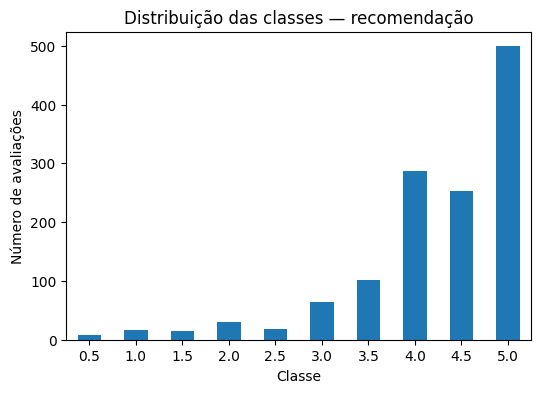

In [ ]:
import matplotlib.pyplot as plt

df["nota_resenha"].value_counts().sort_index().plot(
    kind="bar",
    figsize=(6, 4)
)

plt.title("Distribuição das classes — recomendação")
plt.xlabel("Classe")
plt.ylabel("Número de avaliações")
plt.xticks(rotation=0)
plt.show()

In [ ]:
X = df["resenha_limpa"]
y = df["nota_resenha"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Treino:", len(X_train))
print("Teste:", len(X_test))


Treino: 1034
Teste: 259


In [ ]:
modelo_binario = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            lowercase=True,
            min_df=2,
            max_df=0.95,
            ngram_range=(1, 2),
            max_features=20_000
        )
    ),
    (
        "classificador",
        LogisticRegression(
            max_iter=1000,
            random_state=RANDOM_STATE
        )
    )
])

modelo_binario.fit(X_train, y_train)


Pipeline(steps=[('tfidf',
                 TfidfVectorizer(max_df=0.95, max_features=20000, min_df=2,
                                 ngram_range=(1, 2))),
                ('classificador',
                 LogisticRegression(max_iter=1000, random_state=42))])

In [ ]:
y_pred = modelo_binario.predict(X_test)

print(f"Acurácia: {accuracy_score(y_test, y_pred):.3f}\n")
print(classification_report(y_test, y_pred, digits=3))


Acurácia: 0.363

              precision    recall  f1-score   support

         0.5      0.000     0.000     0.000         2
         1.0      0.000     0.000     0.000         3
         1.5      0.000     0.000     0.000         3
         2.0      0.000     0.000     0.000         6
         2.5      0.000     0.000     0.000         4
         3.0      0.000     0.000     0.000        13
         3.5      0.000     0.000     0.000        20
         4.0      0.240     0.105     0.146        57
         4.5      0.071     0.020     0.031        51
         5.0      0.395     0.870     0.544       100

    accuracy                          0.363       259
   macro avg      0.071     0.099     0.072       259
weighted avg      0.220     0.363     0.248       259



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning:

Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning:

Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning:

Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.



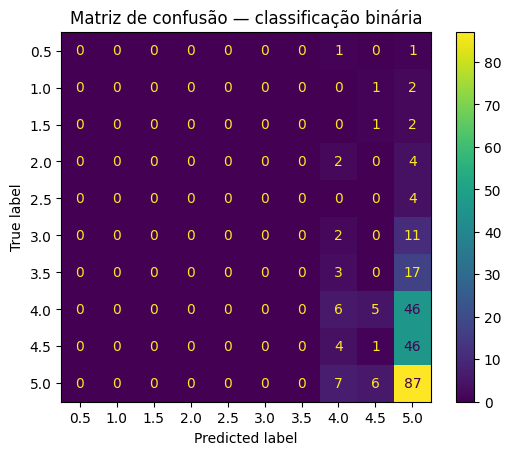

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    cmap=None
)

plt.title("Matriz de confusão — classificação binária")
plt.show()


In [ ]:
vetorizador = modelo_binario.named_steps["tfidf"]
classificador = modelo_binario.named_steps["classificador"]

termos = vetorizador.get_feature_names_out()
coeficientes = classificador.coef_[0]

coef_df = pd.DataFrame({
    "termo": termos,
    "coeficiente": coeficientes
}).sort_values("coeficiente")

print("Classes do modelo:", classificador.classes_)


Classes do modelo: ['0.5' '1.0' '1.5' '2.0' '2.5' '3.0' '3.5' '4.0' '4.5' '5.0']


In [ ]:
print("Termos mais associados à primeira direção da decisão:")
coef_df.head(15)


Termos mais associados à primeira direção da decisão:


,termo,coeficiente
1888,my,-0.096616
2483,so,-0.085226
1637,like,-0.078180
1193,he,-0.074705
2030,on,-0.072189
3156,was,-0.071326
78,all,-0.067981
3251,when,-0.064208
462,can,-0.061272
1179,have,-0.059157


In [ ]:
print("Termos mais associados à direção oposta:")
coef_df.tail(15).sort_values("coeficiente", ascending=False)


Termos mais associados à direção oposta:


,termo,coeficiente
942,film,0.519237
2795,the real,0.439294
2156,picture showcase,0.403983
2451,showcase film,0.403983
344,best picture,0.389107
2450,showcase,0.389032
2155,picture,0.339753
1408,is film,0.336778
1224,here is,0.336109
3295,whoever,0.335537


In [ ]:
novos_textos = [
    "Best war movie I've seen in years.",
    "what if i said pixars best film what then",
    "This movie DESTROYED me.",
    "Probably the funniest movie ever made."
    ]

previsoes = modelo_binario.predict(novos_textos)
probabilidades = modelo_binario.predict_proba(novos_textos)

resultado_novos = pd.DataFrame({
    "texto": novos_textos,
    "classe_prevista": previsoes,
    f"prob_{classificador.classes_[0]}": probabilidades[:, 0],
    f"prob_{classificador.classes_[1]}": probabilidades[:, 1]
})

resultado_novos


,texto,classe_prevista,prob_0.5,prob_1.0
0,Best war movie I've seen in years.,5.0,0.005159,0.012336
1,what if i said pixars best film what then,5.0,0.005716,0.013948
2,This movie DESTROYED me.,5.0,0.006258,0.018197
3,Probably the funniest movie ever made.,5.0,0.004869,0.013035


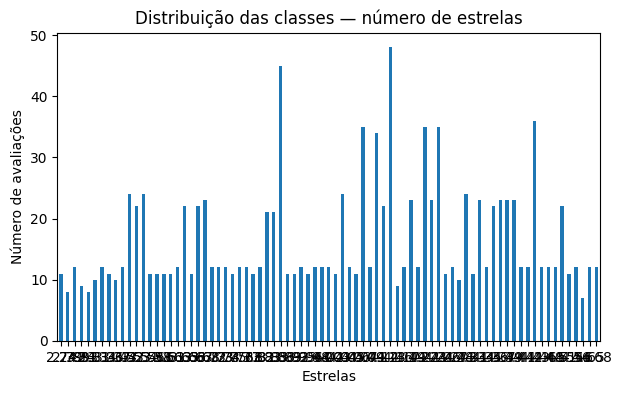

In [ ]:
df["nota_media_letterboxd"].value_counts().sort_index().plot(
    kind="bar",
    figsize=(7, 4)
)

plt.title("Distribuição das classes — número de estrelas")
plt.xlabel("Estrelas")
plt.ylabel("Número de avaliações")
plt.xticks(rotation=0)
plt.show()


In [ ]:
X_multi = df["resenha_limpa"]
y_multi = df["nota_resenha"]

X_train_multi, X_test_multi, y_train_multi, y_test_multi = train_test_split(
    X_multi,
    y_multi,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_multi
)

print("Classes:", sorted(y_multi.unique()))


Classes: ['0.5', '1.0', '1.5', '2.0', '2.5', '3.0', '3.5', '4.0', '4.5', '5.0']


In [ ]:
from sklearn.linear_model import Ridge

modelo_multiclasse = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            lowercase=True,
            min_df=2,
            max_df=0.95,
            ngram_range=(1, 2),
            max_features=20_000
        )
    ),
    (
        "classificador",
        Ridge(
            random_state=RANDOM_STATE
        )
    )
])

modelo_multiclasse.fit(X_train_multi, y_train_multi)

Pipeline(steps=[('tfidf',
                 TfidfVectorizer(max_df=0.95, max_features=20000, min_df=2,
                                 ngram_range=(1, 2))),
                ('classificador', Ridge(random_state=42))])

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae_multi = mean_absolute_error(y_test_multi, y_pred_multi)
mse_multi = mean_squared_error(y_test_multi, y_pred_multi)
r2_multi = r2_score(y_test_multi, y_pred_multi)

print("=== Métricas de Avaliação da Regressão (Nota Média Letterboxd) ===")
print(f"Erro Absoluto Médio (MAE): {mae_multi:.4f}")
print(f"Erro Quadrático Médio (MSE): {mse_multi:.4f}")
print(f"Coeficiente de Determinação (R²): {r2_multi:.4f}")

=== Métricas de Avaliação da Regressão (Nota Média Letterboxd) ===
Erro Absoluto Médio (MAE): 0.7571
Erro Quadrático Médio (MSE): 0.9088
Coeficiente de Determinação (R²): -0.0717


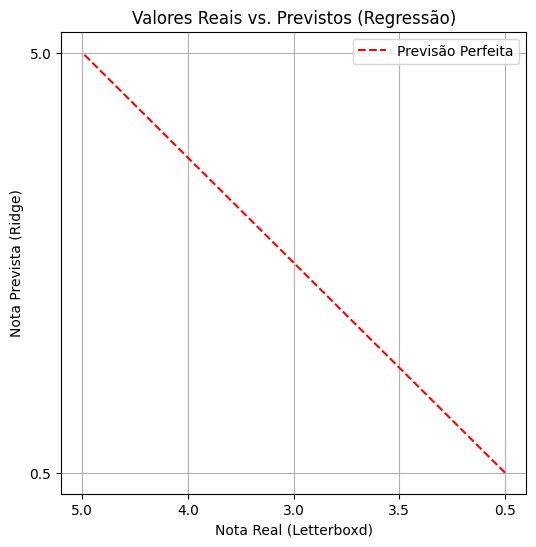

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(6, 6))
plt.scatter(y_test_multi, y_pred_multi, alpha=0.5, color="purple")

limites = [y_test_multi.min(), y_test_multi.max()]
plt.plot(limites, limites, color="red", linestyle="--", label="Previsão Perfeita")

plt.title("Valores Reais vs. Previstos (Regressão)")
plt.xlabel("Nota Real (Letterboxd)")
plt.ylabel("Nota Prevista (Ridge)")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
erros = pd.DataFrame({
    "texto": X_test_multi,
    "real": pd.to_numeric(y_test_multi, errors="coerce"),
    "previsto": pd.to_numeric(y_pred_multi, errors="coerce")
})

erros = erros[erros["real"] != erros["previsto"]].copy()
erros["distancia"] = (erros["real"] - erros["previsto"]).abs()

erros.sort_values(
    ["distancia", "real"],
    ascending=[False, True]
).head(15)

,texto,real,previsto,distancia
385,"Move over, Triumph of the Will. We've got a fr...",0.5,4.063370,3.563370
735,bad haircut,0.5,3.923125,3.423125
386,"This is like, some kind of weird, conservative...",1.0,3.990322,2.990322
176,I don't get the hype that this movie gets.,1.0,3.967646,2.967646
158,"""I don't have time to be their cautionary tale.""",1.0,3.870067,2.870067
161,Everything you need to know about “Bohemian Rh...,1.5,4.002439,2.502439
594,the only political statement this film makes i...,1.5,3.926293,2.426293
1359,i’m gonna jump from a wuthering height,1.5,3.752375,2.252375
591,I have this whole series of YouTube videos tha...,2.0,4.055504,2.055504
1361,WHY IS THERE PONY PLAY IN WUTHERING HEIGHTS WH...,2.0,4.005053,2.005053


In [ ]:
# Converter ambos para o formato numérico antes de realizar a subtração
y_test_num = pd.to_numeric(y_test_multi, errors="coerce").to_numpy()
y_pred_num = pd.to_numeric(y_pred_multi, errors="coerce")

erro_absoluto_medio = (
    pd.Series(y_test_num)
    .sub(pd.Series(y_pred_num))
    .abs()
    .mean()
)

print(
    "Diferença absoluta média entre estrelas reais e previstas:",
    round(erro_absoluto_medio, 3)
)

Diferença absoluta média entre estrelas reais e previstas: 0.757


parse


In [ ]:
%pip -q install spacy pandas networkx matplotlib
!python -m spacy download en_core_web_sm

import spacy
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from spacy import displacy

nlp = spacy.load("en_core_web_sm")
print("spaCy:", spacy.__version__, "| Modelo:", nlp.meta["version"])

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 35.3 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.
spaCy: 3.8.16 | Modelo: 3.8.0


In [ ]:
frases = [
    "The protagonist's performance was simply spectacular and thrilling.",
    "The script for this science fiction film loses its way in the second half.",
    "Hans Zimmer's cinematography and soundtrack save a confusing direction.",
    "I don't understand the critical acclaim for such a predictable thriller.",
    "A horror classic that manages to hold the viewer's attention from beginning to end."
]

frases

["The protagonist's performance was simply spectacular and thrilling.",
 'The script for this science fiction film loses its way in the second half.',
 "Hans Zimmer's cinematography and soundtrack save a confusing direction.",
 "I don't understand the critical acclaim for such a predictable thriller.",
 "A horror classic that manages to hold the viewer's attention from beginning to end."]

In [ ]:
def analisar_dependencias(texto):
    doc = nlp(texto)

    dados = [
        {
            "token": token.text,
            "lema": token.lemma_,
            "classe": token.pos_,
            "dependência": token.dep_,
            "núcleo": token.head.text
        }
        for token in doc
    ]

    return pd.DataFrame(dados)

analisar_dependencias(frases[0])


,token,lema,classe,dependência,núcleo
0,The,the,DET,det,protagonist
1,protagonist,protagonist,NOUN,poss,performance
2,'s,'s,PART,case,protagonist
3,performance,performance,NOUN,nsubj,was
4,was,be,AUX,ROOT,was
5,simply,simply,ADV,advmod,was
6,spectacular,spectacular,ADJ,acomp,was
7,and,and,CCONJ,cc,spectacular
8,thrilling,thrilling,ADJ,conj,spectacular
9,.,.,PUNCT,punct,was


In [ ]:
analisar_dependencias(frases[3])


,token,lema,classe,dependência,núcleo
0,I,I,PRON,nsubj,understand
1,do,do,AUX,aux,understand
2,n't,not,PART,neg,understand
3,understand,understand,VERB,ROOT,understand
4,the,the,DET,det,acclaim
5,critical,critical,ADJ,amod,acclaim
6,acclaim,acclaim,NOUN,dobj,understand
7,for,for,ADP,prep,acclaim
8,such,such,DET,predet,thriller
9,a,a,DET,det,thriller


In [ ]:
for indice in [0, 2]:
    displacy.render(nlp(frases[indice]), style="dep", jupyter=True,
                    options={"compact": True, "distance": 100})


In [ ]:
frases_ner = [
    "You know how there are some movies that are clearly too good to be on Disney but they somehow are anyway?",
    "End of evangelion but for people who go to therapy",
    "lowkey? one of the best Pixar films",
    "heath ledger: *dances down steps with giant leaps*",
    "Minecraft cave noises prepared me for this",
    "summer: i love the smiths."
]

frases_ner


['You know how there are some movies that are clearly too good to be on Disney but they somehow are anyway?',
 'End of evangelion but for people who go to therapy',
 'lowkey? one of the best Pixar films',
 'heath ledger: *dances down steps with giant leaps*',
 'Minecraft cave noises prepared me for this',
 'summer: i love the smiths.']

In [ ]:
def extrair_entidades(texto):
    return pd.DataFrame([
        {"entidade": ent.text, "categoria": ent.label_,
         "início": ent.start_char, "fim": ent.end_char}
        for ent in nlp(texto).ents
    ], columns=["entidade", "categoria", "início", "fim"])

extrair_entidades(frases_ner[1])


,entidade,categoria,início,fim


In [ ]:
nlp.get_pipe("ner").labels


('CARDINAL',
 'DATE',
 'EVENT',
 'FAC',
 'GPE',
 'LANGUAGE',
 'LAW',
 'LOC',
 'MONEY',
 'NORP',
 'ORDINAL',
 'ORG',
 'PERCENT',
 'PERSON',
 'PRODUCT',
 'QUANTITY',
 'TIME',
 'WORK_OF_ART')

In [ ]:
# para extrair nomes de pessoas ele é eficiente, porém, os nomes precisam estar com
# a primeira inicial maiscula. O EVER (palavra toda em maisculo)
# que considerou como ORG é referente a uma
# associação europeia, quando a palavra é "ever" ele não considera
# a categoria correta do filme Call Me By Your Name seria WORK_OF_ART mas
# em relação a isso pode ocorrer erros também

In [ ]:
displacy.render(nlp(frases_ner[0]), style="ent", jupyter=True)


In [ ]:
texto = """
Mila Kunis going down on Natalie Portman IS modern cinema.
So strange that life goes on after finishing a film like Call Me By Your Name.
Do not ever, EVER, travel anywhere with Matt Damon
"""

extrair_entidades(texto)

,entidade,categoria,início,fim
0,Mila Kunis,PERSON,1,11
1,Natalie Portman,PERSON,26,41
2,Call Me By Your Name,ORG,117,137
3,EVER,ORG,152,156
4,Matt Damon\n,PERSON,179,190


In [ ]:
frases_relacoes = [
    "Finally they cast Michael A. Jordan in something.",
    "Everyone involved in this deserves recognition but if anyone should get that ‘best actor’ award this year, it’s Riz. And it isn’t even close!."
]

frases_relacoes


['Finally they cast Michael A. Jordan in something.',
 'Everyone involved in this deserves recognition but if anyone should get that ‘best actor’ award this year, it’s Riz. And it isn’t even close!.']

In [ ]:
doc = nlp(frases_relacoes[1])
pd.DataFrame([
    {"função": token.dep_, "núcleo": token.text,
     "sintagma": " ".join(t.text for t in token.subtree)}
    for token in doc if token.dep_ in {"nsubj", "nsubjpass", "dobj"}
])

,função,núcleo,sintagma
0,nsubj,Everyone,Everyone involved in this
1,dobj,recognition,recognition
2,nsubj,anyone,anyone
3,dobj,award,that ‘ best actor ’ award
4,nsubj,it,it
5,nsubj,it,it


In [ ]:
def obter_sintagma(token):
    tokens = list(token.subtree)

    inicio = min(t.i for t in tokens)
    fim = max(t.i for t in tokens) + 1

    return token.doc[inicio:fim].text


def extrair_relacao_svo(texto):
    doc = nlp(texto)

    for verbo in doc:
        if verbo.pos_ == "VERB":
            sujeitos = [t for t in verbo.children if t.dep_ in {"nsubj", "nsubjpass"}]
            objetos = [t for t in verbo.children if t.dep_ in {"dobj", "dative"}]

            for sujeito in sujeitos:
                for objeto in objetos:
                    return {
                        "sujeito": obter_sintagma(sujeito),
                        "relação": verbo.lemma_,
                        "objeto": obter_sintagma(objeto)
                    }

    return None

extrair_relacao_svo(frases_relacoes[0])

{'sujeito': 'they', 'relação': 'cast', 'objeto': 'Michael A. Jordan'}

In [ ]:
pd.DataFrame([
    {"frase": frase, "tripla SVO": extrair_relacao_svo(frase)}
    for frase in frases_relacoes
])


,frase,tripla SVO
0,Finally they cast Michael A. Jordan in something.,"{'sujeito': 'they', 'relação': 'cast', 'objeto..."
1,Everyone involved in this deserves recognition...,"{'sujeito': 'Everyone involved in this', 'rela..."


In [ ]:
analisar_dependencias(frases_relacoes[0])


,token,lema,classe,dependência,núcleo
0,Finally,finally,ADV,advmod,cast
1,they,they,PRON,nsubj,cast
2,cast,cast,VERB,ROOT,cast
3,Michael,Michael,PROPN,compound,Jordan
4,A.,A.,PROPN,compound,Jordan
5,Jordan,Jordan,PROPN,dobj,cast
6,in,in,ADP,prep,cast
7,something,something,PRON,pobj,in
8,.,.,PUNCT,punct,cast


In [ ]:
def obter_argumento(token):
    entidade = next((ent for ent in token.doc.ents
                     if ent.start <= token.i < ent.end), None)
    if entidade is not None:
        return entidade.text
    tokens = sorted((t for t in token.subtree if not t.is_punct),
                    key=lambda t: t.i)
    while tokens and tokens[0].dep_ in {"det", "case"}:
        tokens.pop(0)
    return " ".join(t.text for t in tokens)


def normalizar_preposicao(token):
    mapa = {
        **dict.fromkeys(["onto", "upon"], "on"),
        **dict.fromkeys(["within", "inside"], "in"),
        **dict.fromkeys(["unto"], "to"),
        **dict.fromkeys(["towards"], "toward"),
        **dict.fromkeys(["amongst"], "among"),
        **dict.fromkeys(["amidst"], "amid"),
        **dict.fromkeys(["thru"], "through"),
        **dict.fromkeys(["til", "till"], "until"),
        **dict.fromkeys(["w/"], "with"),
    }
    return mapa.get(token.text.lower(), token.lemma_.lower())

In [ ]:
import re

PRONOMES_PERMITIDOS = {"i", "we", "they"}

def _argumento_valido(token):
    return not (token.pos_ == "PRON" and token.text.lower() not in PRONOMES_PERMITIDOS)

def sujeitos_do_verbo(verbo):
    atual = verbo
    for _ in range(3):
        suj = [t for t in atual.children if t.dep_ in {"nsubj", "nsubjpass"}]
        if suj:
            return suj
        if atual.dep_ in {"xcomp", "conj", "advcl"} and atual.head is not atual:
            atual = atual.head
        else:
            break
    return []

def extrair_relacoes_doc(doc, normalizar=True):
    argumento = obter_argumento if normalizar else obter_sintagma
    saida = []
    for verbo in doc:
        if verbo.pos_ != "VERB":
            continue
        sujeitos = sujeitos_do_verbo(verbo)
        if not sujeitos:
            continue
        negado = any(t.dep_ == "neg" for t in verbo.children)
        passiva = any(t.dep_ in {"nsubjpass", "auxpass"} for t in verbo.children)
        base = ("not_" if negado else "") + ("be_" if passiva else "") + verbo.lemma_.lower()

        complementos = []                                   # (token, relação)
        for filho in verbo.children:
            if filho.dep_ in {"dobj", "dative"}:
                complementos.append((filho, base))
            elif filho.dep_ in {"prep", "agent"}:
                for obj in filho.children:
                    if obj.dep_ == "pobj":
                        complementos.append((obj, f"{base}_{normalizar_preposicao(filho)}"))

        for suj in sujeitos:
            for comp, relacao in complementos:
                if _argumento_valido(suj) and _argumento_valido(comp):
                    saida.append({"sujeito": argumento(suj), "relação": relacao,
                                  "objeto": argumento(comp)})
    return pd.DataFrame(saida, columns=["sujeito", "relação", "objeto"])


def extrair_relacoes(texto, normalizar=True):
    return extrair_relacoes_doc(nlp(re.sub(r"\s+", " ", texto).strip()), normalizar)


extrair_relacoes(frases_relacoes[0])

,sujeito,relação,objeto
0,they,cast,Michael A. Jordan


In [ ]:
frases_relacoes = [
    "I like to imagine that the ghost of Johnny Cash haunts James Mangold.",
    "Just found out Awkwafina was originally cast as the daughter and now I’m even more thankful to be in the universe where that didn’t happen.",
    "I can't believe they made a remake of Walk Hard but left out all the jokes.",
    "These oners must’ve been very demanding on MacKay and Chapman and yet they gave really natural performances.",
    "It used to be that every white male wanted to write the next great American novel and now it’s every white male filmmaker wants to make the next great “provocative” movie, and it’s tiring.",
]

comparacao = pd.concat([
    extrair_relacoes(frase, normalizar=opcao).assign(
        versão="normalizada" if opcao else "bruta", frase=frase[:60] + "…")
    for opcao in [False, True] for frase in frases_relacoes
], ignore_index=True)
relacoes_df = comparacao.loc[comparacao["versão"] == "normalizada",
                             ["sujeito", "relação", "objeto"]].copy()
comparacao

,sujeito,relação,objeto,versão,frase
0,I,imagine,that the ghost of Johnny Cash haunts James Man...,bruta,I like to imagine that the ghost of Johnny Cas...
1,Awkwafina,be_cast_as,the daughter,bruta,Just found out Awkwafina was originally cast a...
2,they,make,a remake of Walk Hard,bruta,I can't believe they made a remake of Walk Har...
3,I,leave,all the jokes,bruta,I can't believe they made a remake of Walk Har...
4,they,give,really natural performances,bruta,These oners must’ve been very demanding on Mac...
5,every white male,write,the next great American novel,bruta,It used to be that every white male wanted to ...
6,every white male filmmaker,make,the next great “provocative” movie,bruta,It used to be that every white male wanted to ...
7,I,imagine,that the ghost of Johnny Cash haunts James Man...,normalizada,I like to imagine that the ghost of Johnny Cas...
8,Awkwafina,be_cast_as,daughter,normalizada,Just found out Awkwafina was originally cast a...
9,they,make,remake of Walk Hard,normalizada,I can't believe they made a remake of Walk Har...


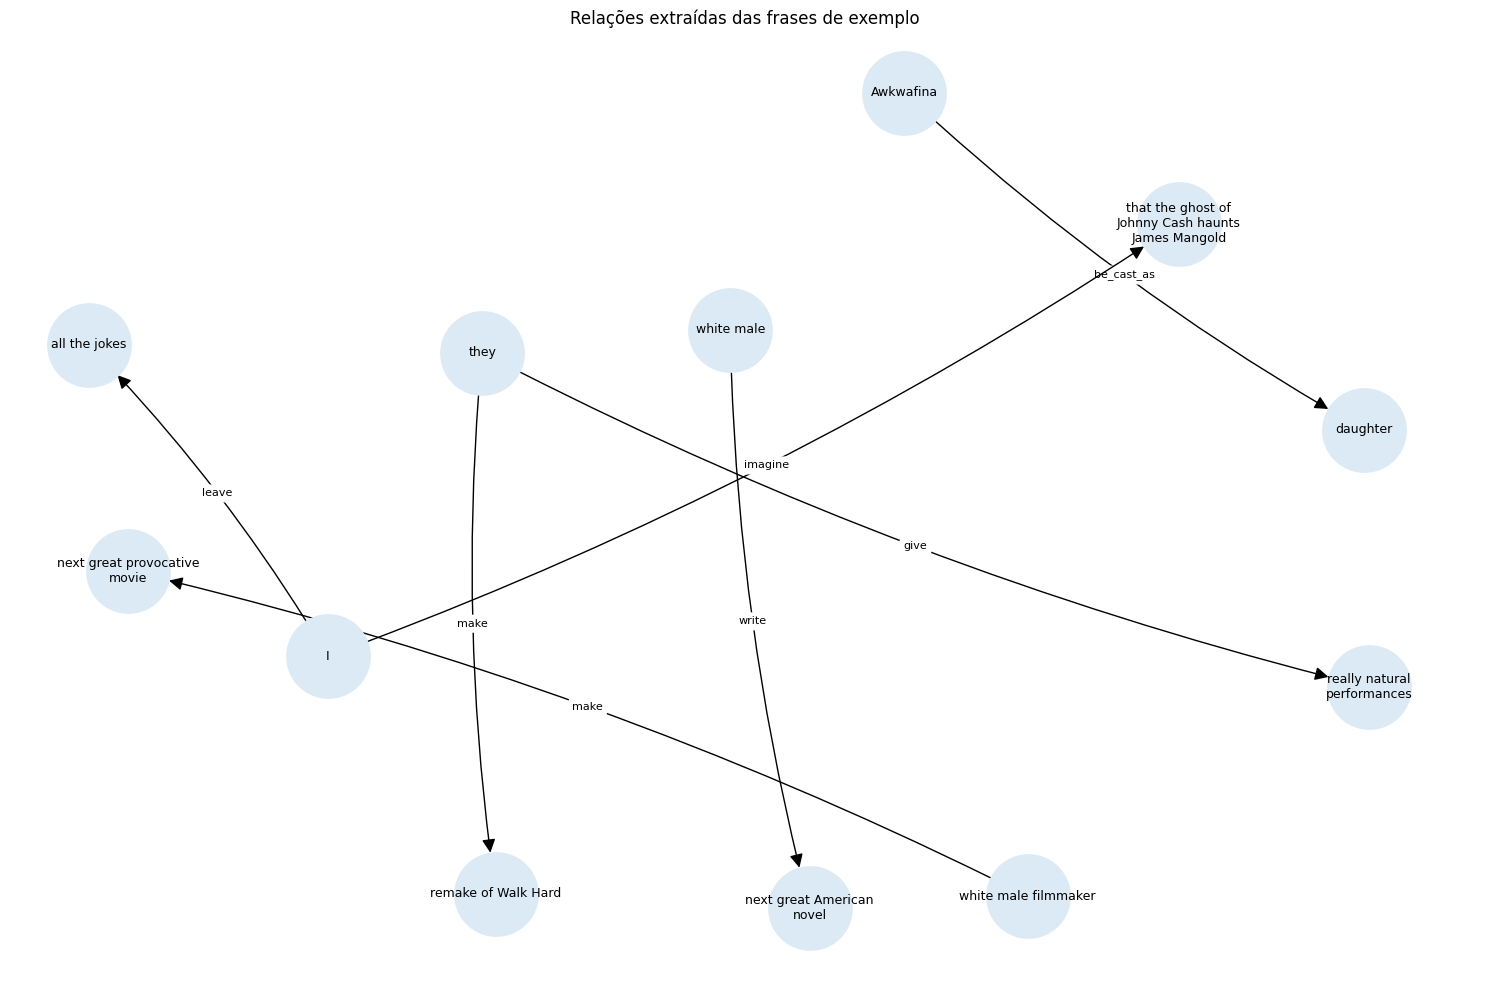

Nós: 12 | Pares direcionados: 7


In [ ]:
import textwrap


def desenhar_grafo(tabela, titulo):
    grafo = nx.DiGraph()
    for (origem, destino), grupo in tabela.groupby(["sujeito", "objeto"], sort=True):
        grafo.add_edge(origem, destino,
                       relação=", ".join(sorted(set(grupo["relação"]))))
    fig, ax = plt.subplots(figsize=(15, 10))
    pos = nx.spring_layout(grafo, seed=42, k=1.8)
    nx.draw_networkx_nodes(grafo, pos, node_size=3600, node_color="#dceaf5", ax=ax)
    nomes = {n: textwrap.fill(n, width=22) for n in grafo.nodes}
    nx.draw_networkx_labels(grafo, pos, labels=nomes, font_size=9, ax=ax)
    # Desenhar uma aresta por vez permite separar relações recíprocas.
    for origem, destino, dados in grafo.edges(data=True):
        curva = 0.25 if grafo.has_edge(destino, origem) else 0.06
        nx.draw_networkx_edges(grafo, pos, edgelist=[(origem, destino)],
                               arrows=True, arrowsize=20, node_size=3600,
                               connectionstyle=f"arc3,rad={curva}", ax=ax)
        nx.draw_networkx_edge_labels(
            grafo, pos, edge_labels={(origem, destino):
                textwrap.fill(dados["relação"], width=24)},
            font_size=8, rotate=False, node_size=3600,
            connectionstyle=f"arc3,rad={curva}", ax=ax)
    ax.set_title(titulo)
    ax.axis("off")
    plt.tight_layout()
    plt.show()
    print(f"Nós: {grafo.number_of_nodes()} | Pares direcionados: {grafo.number_of_edges()}")
    return grafo

G_exemplos = desenhar_grafo(relacoes_df, "Relações extraídas das frases de exemplo")


In [ ]:
texto_longo = """
oh. what do you do when one day you wake up and look at your life and realize this
was never the life you were supposed to have? and you realize that the man who loves
you isn't someone you can respect, and the one man you respect isn't someone you can
forgive? (do you choose your home or your mirror?) worse, how do you confess that you'd
trade your husband and the daughter you made together in a heartbeat for the unbroken knee
that could've made you the greatest in the world?"""


In [ ]:
doc_longo = nlp(texto_longo.strip())
sentencas = [sent.text.strip() for sent in doc_longo.sents]
pd.DataFrame([
    {"sentença": i, "texto": sent.text.strip(),
     "entidades": [(ent.text, ent.label_) for ent in sent.ents]}
    for i, sent in enumerate(doc_longo.sents, start=1)
])


,sentença,texto,entidades
0,1,oh.,[]
1,2,what do you do when one day you wake up and lo...,"[(one day, DATE)]"
2,3,and you realize that the man who loves \nyou i...,"[(one, CARDINAL)]"
3,4,(do you choose your home or your mirror?),[]
4,5,"worse, how do you confess that you'd \ntrade y...",[]


In [ ]:
resultados = [
    extrair_relacoes(sentenca).assign(sentença=i, texto=sentenca)
    for i, sentenca in enumerate(sentencas, start=1)
]
relacoes_texto_df = (pd.concat(resultados, ignore_index=True) if resultados
                    else pd.DataFrame(columns=["sujeito", "relação", "objeto",
                                               "sentença", "texto"]))
relacoes_texto_df[["sentença", "sujeito", "relação", "objeto", "texto"]]


,sentença,sujeito,relação,objeto,texto


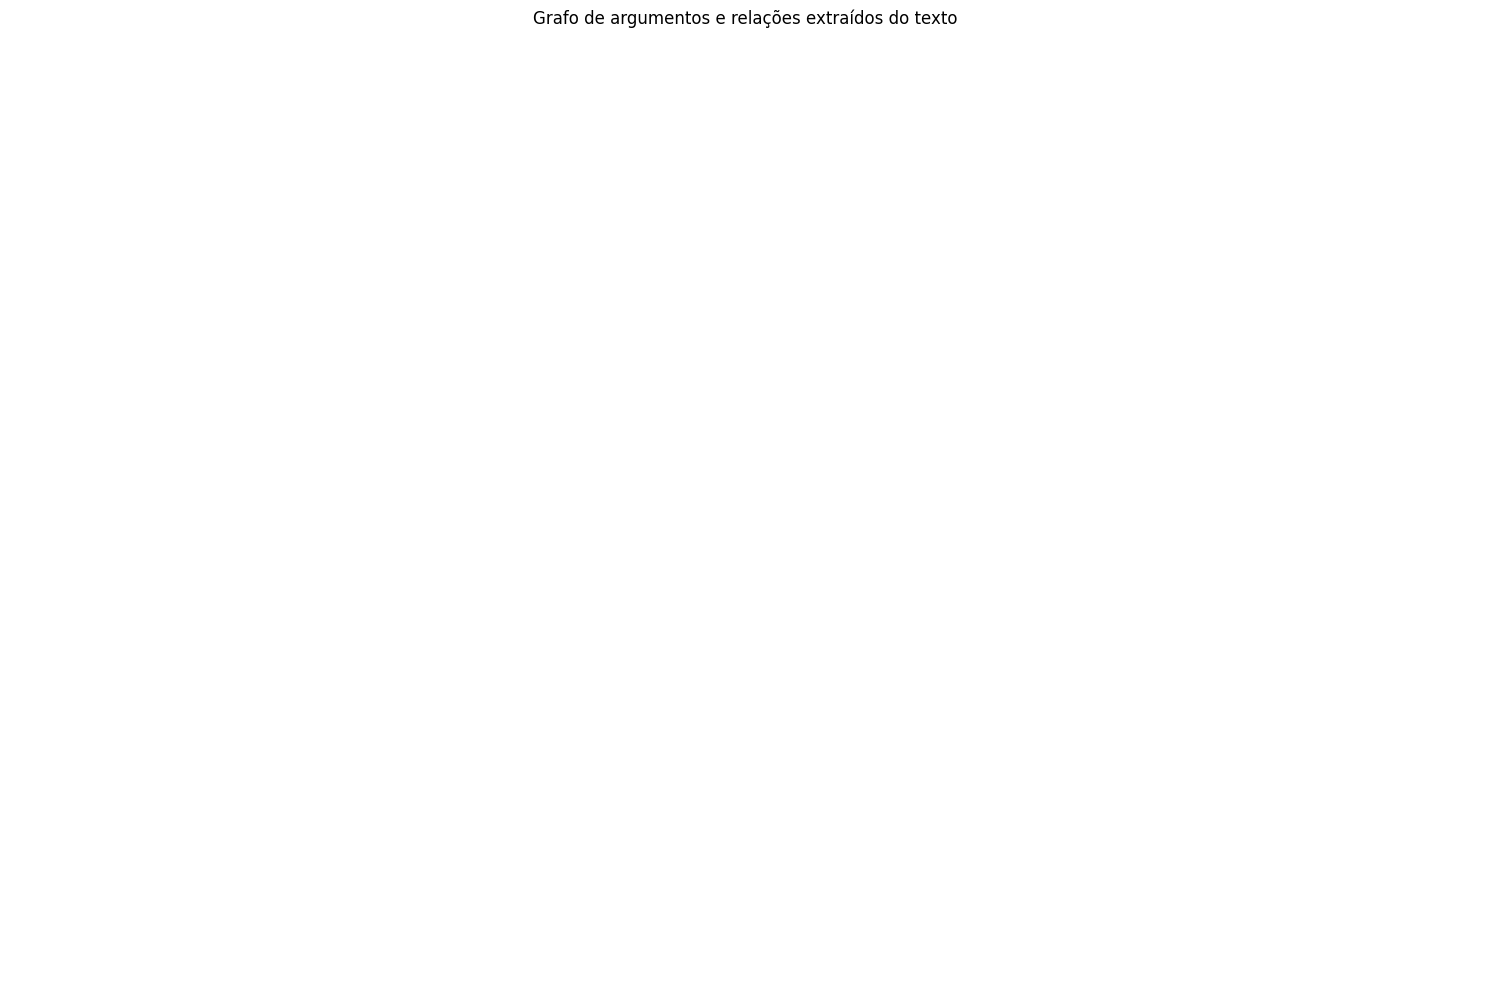

Nós: 0 | Pares direcionados: 0


In [ ]:
G_texto = desenhar_grafo(relacoes_texto_df, "Grafo de argumentos e relações extraídos do texto")


In [ ]:
!pip install -q transformers torch

In [ ]:
import pandas as pd
import torch
from transformers import pipeline
from tqdm.auto import tqdm

# Selecionar o dispositivo de execução
device = 0 if torch.cuda.is_available() else -1

# Carregar o modelo de sentimentos
analisador = pipeline(
    "sentiment-analysis",
    model="nlptown/bert-base-multilingual-uncased-sentiment",
    device=device
)

# Usar as resenhas originais, sem stemming ou remoção de stopwords
textos = (
    df["resenha_original"]
    .fillna("")
    .astype(str)
    .tolist()
)

# Limitar o tamanho dos textos para o modelo
textos = [texto[:1500] for texto in textos]

# Analisar as resenhas em lotes
resultados = []

for inicio in tqdm(range(0, len(textos), 16)):
    lote = textos[inicio:inicio + 16]

    predicoes = analisador(
        lote,
        truncation=True,
        max_length=512
    )

    resultados.extend(predicoes)

# Guardar os resultados na base
df["sentimento_nota"] = [
    int(resultado["label"].split()[0])
    for resultado in resultados
]

df["sentimento_confianca"] = [
    resultado["score"]
    for resultado in resultados
]

# Converter a escala de estrelas em categorias
def classificar_sentimento(nota):
    if nota <= 2:
        return "Negativo"
    elif nota == 3:
        return "Neutro"
    else:
        return "Positivo"

df["sentimento"] = df["sentimento_nota"].apply(
    classificar_sentimento
)

df[[
    "filme",
    "resenha_original",
    "nota_resenha",
    "sentimento_nota",
    "sentimento_confianca",
    "sentimento"
]].head(10)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

  0%|          | 0/81 [00:00<?, ?it/s]

,filme,resenha_original,nota_resenha,sentimento_nota,sentimento_confianca,sentimento
0,10 Things I Hate About You,the moral of the story is that all men are evi...,5.0,1,0.269418,Negativo
1,10 Things I Hate About You,kat stratford is the most relatable character ...,5.0,1,0.321497,Negativo
2,10 Things I Hate About You,me: i hate cliches,5.0,1,0.577521,Negativo
3,10 Things I Hate About You,funny how shakespeare’s been real quiet since ...,5.0,5,0.485101,Positivo
4,10 Things I Hate About You,heath ledger: *dances down steps with giant le...,3.5,4,0.322166,Positivo
5,10 Things I Hate About You,I hate the way this film romanticizes the hard...,4.0,2,0.406459,Negativo
6,10 Things I Hate About You,"dear men, what’s stopping you from being like ...",5.0,5,0.325692,Positivo
7,10 Things I Hate About You,"heath ledger with his hair tied up, covered in...",5.0,2,0.349031,Negativo
8,10 Things I Hate About You,this is the best high school film bc it includ...,4.0,5,0.781683,Positivo
9,10 Things I Hate About You,the scene where bianca finally realises boys a...,5.0,3,0.260125,Neutro


Quantidade de resenhas por sentimento:
sentimento
Negativo    518
Neutro      151
Positivo    624
Name: count, dtype: int64


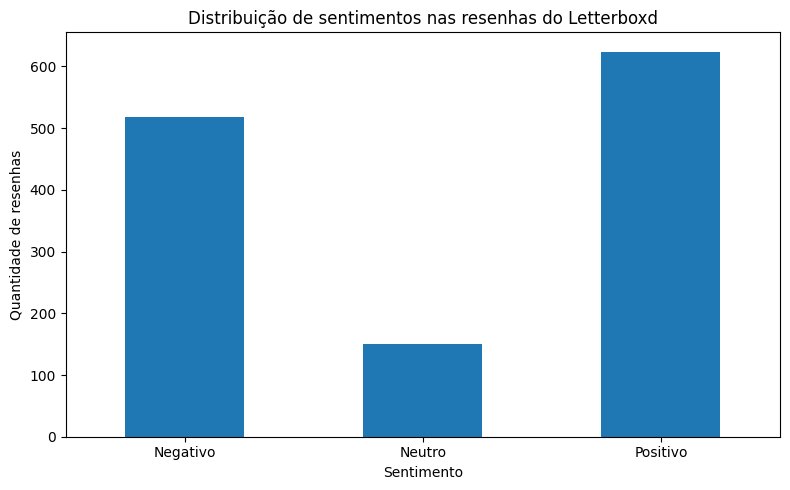

In [ ]:
import matplotlib.pyplot as plt

ordem = ["Negativo", "Neutro", "Positivo"]

contagem = (
    df["sentimento"]
    .value_counts()
    .reindex(ordem, fill_value=0)
)

print("Quantidade de resenhas por sentimento:")
print(contagem)

contagem.plot(
    kind="bar",
    figsize=(8, 5),
    rot=0
)

plt.title("Distribuição de sentimentos nas resenhas do Letterboxd")
plt.xlabel("Sentimento")
plt.ylabel("Quantidade de resenhas")
plt.tight_layout()
plt.show()

In [ ]:
df["nota_resenha"] = pd.to_numeric(df["nota_resenha"], errors="coerce")
df["sentimento_nota"] = pd.to_numeric(df["sentimento_nota"], errors="coerce")

resumo_filmes = (
    df.groupby("filme")
    .agg(
        total_resenhas=("sentimento", "count"),
        nota_media_usuarios=("nota_resenha", "mean"),
        nota_media_modelo=("sentimento_nota", "mean"),
        percentual_positivo=(
            "sentimento",
            lambda s: (s == "Positivo").mean() * 100
        ),
        percentual_negativo=(
            "sentimento",
            lambda s: (s == "Negativo").mean() * 100
        )
    )
    .round(2)
    .sort_values("percentual_positivo", ascending=False)
)

resumo_filmes.head(15)

,total_resenhas,nota_media_usuarios,nota_media_modelo,percentual_positivo,percentual_negativo
filme,,,,,
"The Good, the Bad and the Ugly",11,4.64,4.45,81.82,9.09
Train Dreams,11,4.27,4.36,81.82,9.09
Paris Is Burning,12,4.71,4.08,75.00,25.00
Sinners,12,4.38,4.00,75.00,25.00
Jackass Forever,12,4.33,4.00,75.00,16.67
The Odyssey,12,4.12,4.17,75.00,16.67
Inglourious Basterds,11,4.86,3.91,72.73,18.18
A Charlie Brown Christmas,10,4.90,3.60,70.00,30.00
Dune: Part Two,12,4.71,3.58,66.67,33.33
